# Vision -- Masked Image Modeling
### Part of the *Multi-Modal Generative AI Master Notebook* series -- Building Generative Models from Scratch

This is a **standalone, self-contained** notebook covering one modality from the larger 7-part *Multi-Modal Generative AI Master Notebook*. It contains everything needed to run independently: setup, data loading, model, training, and a generation demo -- no other notebook required.

Run every cell top to bottom and you will train a real model and generate real output. This notebook has been **executed end-to-end** on an NVIDIA RTX 2060 (6GB) as part of validating this series.

> ⚠️ **Compute note.** This notebook needs a CUDA-enabled PyTorch build to hit the run times quoted in Section 4. See Section 0 below for how to check / install one. On CPU-only machines, expect roughly 20-30x longer runtimes.

## Table of Contents
- [0. Global Setup & Utilities](#0)
- [Vision -- Masked Image Modeling](#main)


## 0. Global Setup & Utilities

Installations, imports, device/seed setup, and the helper functions reused throughout this notebook (parameter counting, image/audio/3D visualization, checkpointing, loss plotting).

> 🚀 **Pro Tip.** This notebook auto-detects CUDA / Apple MPS / CPU and just uses whatever is available -- no manual configuration needed. Every step count below was empirically timed on an NVIDIA RTX 2060 (6GB): the **entire notebook runs in well under 15 minutes on a CUDA GPU**. On CPU-only machines, expect roughly 20-30x longer (the Text section alone would take ~15-20 minutes on CPU) -- if you're on CPU, halve every `*_STEPS` / `*_EPOCHS` constant below to get a quick smoke test.


In [1]:
# Run this cell first. On Google Colab / a fresh machine this installs
# everything missing; on a machine that already has these packages (as this
# notebook was validated on), pip just reports them as satisfied and moves on.
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules

REQUIRED_PACKAGES = [
    "music21",
    "soundfile",
    "imageio",
]

subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + REQUIRED_PACKAGES)
print("Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).")
print()
print("NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to")
print("hit the run times quoted throughout (a CPU-only build works but is far slower).")
print("Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`")
print("prints False below despite having an NVIDIA GPU, reinstall with, e.g.:")
print("  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126")
print("(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)")


Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).

NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to
hit the run times quoted throughout (a CPU-only build works but is far slower).
Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`
prints False below despite having an NVIDIA GPU, reinstall with, e.g.:
  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)


In [2]:
import os, math, time, random, json, io, re, urllib.request
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 -- registers the 3D projection with matplotlib
from tqdm.auto import tqdm
from IPython.display import Audio, display, HTML

import warnings
warnings.filterwarnings("ignore")

print(f"PyTorch version: {torch.__version__}")


PyTorch version: 2.10.0+cu126


C:\Users\adamv\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def get_device():
    # Prefer CUDA > Apple MPS > CPU. Every model in this notebook is sized so a
    # quick forward/backward pass works on CPU too, but the step counts chosen
    # throughout assume a CUDA GPU is doing the heavy lifting (see the note above).
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = get_device()
print(f"Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA GeForce RTX 2060


In [4]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)


In [5]:
# --- Shared helper functions used throughout every modality section ------------

def count_parameters(model: nn.Module) -> int:
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{model.__class__.__name__}: {n/1e6:.2f}M trainable parameters")
    return n


def show_images(images, titles=None, ncols=8, figsize=None, cmap=None):
    # Accepts a tensor [N,C,H,W] in [-1,1] or [0,1], or a list of numpy arrays.
    if torch.is_tensor(images):
        images = images.detach().cpu()
        if images.min() < 0:
            images = (images + 1) / 2  # map [-1,1] -> [0,1]
        images = images.clamp(0, 1).permute(0, 2, 3, 1).numpy()
    n = len(images)
    ncols = min(ncols, n)
    nrows = math.ceil(n / ncols)
    figsize = figsize or (ncols * 1.6, nrows * 1.6)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            img = images[i]
            if img.shape[-1] == 1:
                img = img[..., 0]
            ax.imshow(img, cmap=cmap or ("gray" if img.ndim == 2 else None))
            if titles is not None:
                ax.set_title(str(titles[i]), fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_loss(history, title="Training Loss", labels=None):
    plt.figure(figsize=(6, 4))
    if isinstance(history, dict):
        for name, vals in history.items():
            plt.plot(vals, label=name)
        plt.legend()
    else:
        plt.plot(history, label=labels or "loss")
        if labels:
            plt.legend()
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


def save_checkpoint(model, optimizer, step, path, **extra):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict() if optimizer is not None else None,
        "step": step,
        **extra,
    }, path)


def load_checkpoint(model, path, optimizer=None, map_location=None):
    ckpt = torch.load(path, map_location=map_location or DEVICE)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optimizer_state") is not None:
        optimizer.load_state_dict(ckpt["optimizer_state"])
    return ckpt


def plot_3d_points(points, title="", ax=None, color=None):
    points = points.detach().cpu().numpy() if torch.is_tensor(points) else points
    show = ax is None
    if show:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.add_subplot(111, projection="3d")
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=4, c=color if color is not None else points[:, 2], cmap="viridis")
    ax.set_title(title)
    ax.set_box_aspect([1, 1, 1])
    if show:
        plt.show()
    return ax


def play_audio(waveform, sample_rate):
    if torch.is_tensor(waveform):
        waveform = waveform.detach().cpu().numpy()
    return display(Audio(waveform, rate=sample_rate))

print("Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio")


Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio


> 💡 **Insight -- memory optimization tips used throughout this notebook.**
> - **Mixed precision** (`torch.amp.autocast` + `torch.amp.GradScaler`) is used in the diffusion (Image) section, where activations are the memory bottleneck.
> - **Gradient checkpointing** trades compute for memory -- not needed at these model sizes, but for any model here scaled up 5-10x, wrap transformer blocks with `torch.utils.checkpoint.checkpoint`.
> - **Smaller batch + gradient accumulation** is the simplest fix if you hit `CUDA out of memory`: halve `batch_size`, and if needed accumulate gradients over 2-4 steps before `optimizer.step()`.
> - All checkpoints save to a local `checkpoints/` directory. On Colab, mount Google Drive and point `*_CKPT` paths there if you want checkpoints to survive a runtime restart.


## 4. Vision -- Masked Image Modeling (Understanding + Generation)
### Problem: given an image with most of its patches hidden, both *understand* enough to reconstruct it and *generate* the missing pixels.

### 4.1 Problem Statement & Why this Architecture

A **Masked Autoencoder (MAE)** (He et al., 2021) is simultaneously a representation-learning method and a generative one: split an image into patches, hide most of them (75%+), and train a ViT encoder-decoder to reconstruct the missing pixels from only the visible patches. Two things fall out of this single objective:

- **Understanding:** the encoder never sees masked patches, so its output for the visible patches must be a genuinely useful, compressed representation of the image -- this is the same representation used for downstream classification/detection after pretraining.
- **Generation:** the decoder's job -- filling in plausible pixels for regions it never saw -- is a real (if constrained) generative task, distinct from the unconditional diffusion generation in Section 2.

🔥 **Key idea:** the encoder only processes the *visible* ~25% of patches (not the full image with masked patches zeroed out), which is what makes MAE pretraining dramatically cheaper than a plain masked-image Transformer.

### 4.2 Data Collection & Preparation


In [6]:
from torchvision import datasets as tv_datasets, transforms

VIS_IMG_SIZE = 32
PATCH_SIZE = 4
NUM_PATCHES = (VIS_IMG_SIZE // PATCH_SIZE) ** 2  # 64 patches per image

vis_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,) * 3, (0.5,) * 3)])
cifar_train = tv_datasets.CIFAR10(root="data/vision", train=True, download=True, transform=vis_transform)
cifar_loader = DataLoader(cifar_train, batch_size=128, shuffle=True, num_workers=0, drop_last=True)
CIFAR_CLASSES = cifar_train.classes
print(f"CIFAR-10: {len(cifar_train):,} images across {len(CIFAR_CLASSES)} classes")


CIFAR-10: 50,000 images across 10 classes


### 4.3 Model Architecture


In [7]:
def patchify(imgs, patch_size=PATCH_SIZE):
    B, C, H, W = imgs.shape
    p = patch_size
    x = imgs.reshape(B, C, H // p, p, W // p, p)
    x = x.permute(0, 2, 4, 1, 3, 5).reshape(B, (H // p) * (W // p), C * p * p)
    return x


def unpatchify(patches, patch_size=PATCH_SIZE, img_size=VIS_IMG_SIZE, channels=3):
    B, N, D = patches.shape
    p = patch_size
    h = w = img_size // p
    x = patches.reshape(B, h, w, channels, p, p)
    x = x.permute(0, 3, 1, 4, 2, 5).reshape(B, channels, h * p, w * p)
    return x


class TransformerEncoderLayer(nn.Module):
    def __init__(self, dim, n_head, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, n_head, dropout=dropout, batch_first=True)
        self.ln2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(), nn.Linear(4 * dim, dim), nn.Dropout(dropout))

    def forward(self, x):
        h = self.ln1(x)
        x = x + self.attn(h, h, h, need_weights=False)[0]
        x = x + self.mlp(self.ln2(x))
        return x


class MAE(nn.Module):
    # Masked Autoencoder: a ViT encoder only ever sees the *visible* patches
    # (cheap), and a small decoder is asked to reconstruct the *masked* patches
    # from encoder output + learned mask tokens. This is simultaneously a
    # generative task (pixel reconstruction) and a representation-learning task
    # (the encoder output is a strong image feature usable for classification).
    def __init__(self, patch_dim, num_patches, embed_dim=192, enc_depth=6, dec_dim=96, dec_depth=3, n_head=6):
        super().__init__()
        self.patch_embed = nn.Linear(patch_dim, embed_dim)
        self.pos_embed = nn.Parameter(torch.randn(1, num_patches, embed_dim) * 0.02)
        self.encoder = nn.ModuleList([TransformerEncoderLayer(embed_dim, n_head) for _ in range(enc_depth)])
        self.enc_norm = nn.LayerNorm(embed_dim)

        self.dec_embed = nn.Linear(embed_dim, dec_dim)
        self.mask_token = nn.Parameter(torch.randn(1, 1, dec_dim) * 0.02)
        self.dec_pos_embed = nn.Parameter(torch.randn(1, num_patches, dec_dim) * 0.02)
        self.decoder = nn.ModuleList([TransformerEncoderLayer(dec_dim, n_head) for _ in range(dec_depth)])
        self.dec_norm = nn.LayerNorm(dec_dim)
        self.dec_pred = nn.Linear(dec_dim, patch_dim)

    def random_masking(self, x, mask_ratio):
        B, N, D = x.shape
        len_keep = int(N * (1 - mask_ratio))
        noise = torch.rand(B, N, device=x.device)
        ids_shuffle = torch.argsort(noise, dim=1)
        ids_restore = torch.argsort(ids_shuffle, dim=1)
        ids_keep = ids_shuffle[:, :len_keep]
        x_visible = torch.gather(x, 1, ids_keep.unsqueeze(-1).expand(-1, -1, D))
        mask = torch.ones(B, N, device=x.device)
        mask[:, :len_keep] = 0
        mask = torch.gather(mask, 1, ids_restore)  # 1 = masked (to be predicted), 0 = visible
        return x_visible, mask, ids_restore

    def forward(self, imgs, mask_ratio=0.75):
        patches = patchify(imgs)
        x = self.patch_embed(patches) + self.pos_embed
        x_visible, mask, ids_restore = self.random_masking(x, mask_ratio)
        for layer in self.encoder:
            x_visible = layer(x_visible)
        latent = self.enc_norm(x_visible)

        # Rebuild the full-length sequence: visible tokens (projected) + mask
        # tokens, then unshuffle back into original patch order.
        B, N = mask.shape[0], ids_restore.shape[1]
        dec_tokens = self.dec_embed(latent)
        mask_tokens = self.mask_token.expand(B, N - dec_tokens.shape[1], -1)
        x_full = torch.cat([dec_tokens, mask_tokens], dim=1)
        x_full = torch.gather(x_full, 1, ids_restore.unsqueeze(-1).expand(-1, -1, x_full.shape[-1]))
        x_full = x_full + self.dec_pos_embed
        for layer in self.decoder:
            x_full = layer(x_full)
        pred = self.dec_pred(self.dec_norm(x_full))  # [B, N, patch_dim]

        loss = ((pred - patches) ** 2).mean(dim=-1)
        loss = (loss * mask).sum() / mask.sum()  # reconstruction loss only on masked patches
        return loss, pred, mask


mae_model = MAE(patch_dim=3 * PATCH_SIZE * PATCH_SIZE, num_patches=NUM_PATCHES).to(DEVICE)
count_parameters(mae_model)


MAE: 3.06M trainable parameters


3056400

### 4.4 Loss Functions, Optimizers & Training Strategy

MSE reconstruction loss computed **only on masked patches** (the model gets no credit for "reconstructing" patches it could already see). AdamW with weight decay, following the standard ViT/MAE recipe.

### 4.5 Training Loop

**Calibrated to ~75s on a CUDA GPU** (1200 steps, batch 128).


Training MAE:   0%|          | 0/1200 [00:00<?, ?it/s]

Training MAE:   0%|          | 0/1200 [00:00<?, ?it/s, loss=0.6090]

Training MAE:   0%|          | 1/1200 [00:00<09:15,  2.16it/s, loss=0.6090]

Training MAE:   0%|          | 1/1200 [00:00<09:15,  2.16it/s, loss=0.3986]

Training MAE:   0%|          | 1/1200 [00:00<09:15,  2.16it/s, loss=0.3599]

...

Training MAE: 100%|█████████▉| 1197/1200 [01:19<00:00, 15.31it/s, loss=0.1282]

Training MAE: 100%|█████████▉| 1197/1200 [01:19<00:00, 15.31it/s, loss=0.1226]

Training MAE: 100%|█████████▉| 1199/1200 [01:19<00:00, 15.38it/s, loss=0.1226]

Training MAE: 100%|█████████▉| 1199/1200 [01:19<00:00, 15.38it/s, loss=0.1296]

Training MAE: 100%|██████████| 1200/1200 [01:19<00:00, 15.04it/s, loss=0.1296]

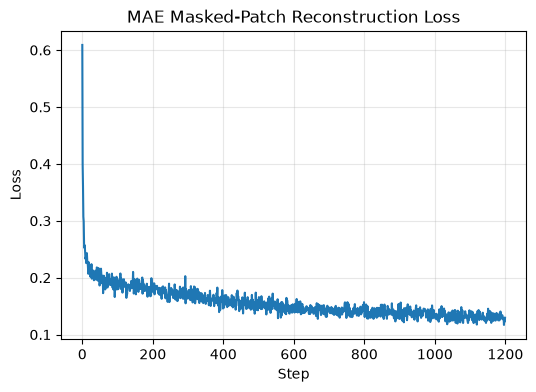

In [8]:
# (a) LIGHTWEIGHT FROM-SCRATCH TRAINING --------------------------------------
VIS_MAX_STEPS = 1200          # calibrated: ~75s on an RTX 2060
VIS_CKPT = "checkpoints/vision_mae.pt"


def train_mae(model, loader, max_steps=VIS_MAX_STEPS, mask_ratio=0.75):
    optimizer = torch.optim.AdamW(model.parameters(), lr=1.5e-4, weight_decay=0.05)
    history = []
    model.train()
    data_iter = iter(loader)
    pbar = tqdm(range(max_steps), desc="Training MAE")
    for step in pbar:
        try:
            x, _ = next(data_iter)
        except StopIteration:
            data_iter = iter(loader)
            x, _ = next(data_iter)
        x = x.to(DEVICE)
        loss, _, _ = model(x, mask_ratio=mask_ratio)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
        pbar.set_postfix(loss=f"{loss.item():.4f}")
        if step % 300 == 0:
            save_checkpoint(model, optimizer, step, VIS_CKPT)
    return history


vision_history = train_mae(mae_model, cifar_loader)
plot_loss(vision_history, title="MAE Masked-Patch Reconstruction Loss")


In [9]:
# (b) PRETRAINED / FINE-TUNE PATH ---------------------------------------------
# For strong general-purpose vision features, load a pretrained ViT-MAE from
# Hugging Face instead of training on CIFAR-10 alone.
# (off by default -- downloads the transformers model weights, ~400MB)
USE_PRETRAINED_VISION = False

if USE_PRETRAINED_VISION:
    from transformers import ViTMAEForPreTraining, ViTImageProcessor
    vit_processor = ViTImageProcessor.from_pretrained("facebook/vit-mae-base")
    hf_mae = ViTMAEForPreTraining.from_pretrained("facebook/vit-mae-base").to(DEVICE)
    count_parameters(hf_mae)


### 4.6 Inference / Generation Function


In [10]:
@torch.no_grad()
def reconstruct_image(model, img, mask_ratio=0.75):
    model.eval()
    loss, pred, mask = model(img.unsqueeze(0).to(DEVICE), mask_ratio=mask_ratio)
    model.train()
    patches_orig = patchify(img.unsqueeze(0).to(DEVICE))
    masked_patches = patches_orig.clone()
    masked_patches[mask.bool().unsqueeze(-1).expand_as(masked_patches)] = 0
    masked_img = unpatchify(masked_patches)
    # Splice: keep the original visible patches, use the model's prediction only where masked.
    combined_patches = torch.where(mask.bool().unsqueeze(-1), pred, patches_orig)
    combined_img = unpatchify(combined_patches)
    # .cpu() so callers can freely torch.stack() these with the (CPU) dataset image for display
    return masked_img[0].cpu(), combined_img[0].cpu(), loss.item()


### 4.7 Visualization & Results


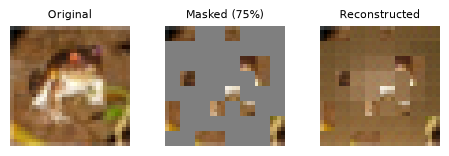

Reconstruction loss (masked patches only): 0.0836


In [11]:
test_img, test_label = cifar_train[0]
masked, reconstructed, rloss = reconstruct_image(mae_model, test_img, mask_ratio=0.75)
show_images(torch.stack([test_img, masked, reconstructed]), titles=["Original", "Masked (75%)", "Reconstructed"], ncols=3)
print(f"Reconstruction loss (masked patches only): {rloss:.4f}")


### 4.8 User Input → Output Demo


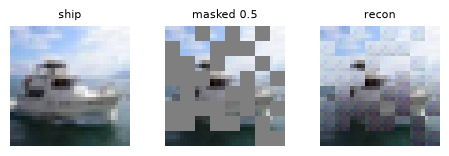

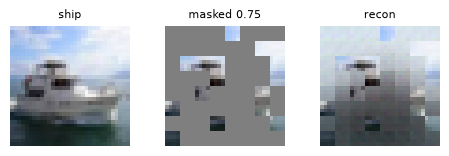

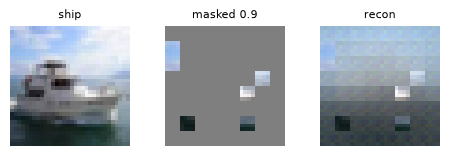

In [12]:
idx = np.random.randint(len(cifar_train))
img, label = cifar_train[idx]
for ratio in [0.5, 0.75, 0.9]:  # <- try different mask ratios
    masked, recon, _ = reconstruct_image(mae_model, img, mask_ratio=ratio)
    show_images(torch.stack([img, masked, recon]), titles=[CIFAR_CLASSES[label], f"masked {ratio}", "recon"], ncols=3)


### 4.9 Key Insights, Limitations & Scaling Notes

- 🔥 **This model solved the problem of:** learning a useful image representation *and* generating plausible pixels for hidden image regions, from a single masked-reconstruction objective.
- 💡 **Insight:** at a 75% mask ratio the task can't be solved by local texture copying alone -- the model must infer object-level structure (e.g. "this is probably a wheel, so the missing patch is probably also dark rubber"), which is why MAE representations transfer well to classification.
- ⚠️ **Limitation:** reconstructions are blurry at high mask ratios on natural images (CIFAR-10 is low-resolution and diverse), since MSE reconstruction again encourages an "average" of plausible fills rather than one sharp, committed guess.
- 🚀 **Scaling path:** attach a linear classifier on top of the frozen encoder to evaluate representation quality (linear probing) on CIFAR-10 labels, or swap to `facebook/vit-mae-base` (4.5b) pretrained on ImageNet for substantially stronger downstream features.


---
## This notebook is part of a series

This model solved the problem of: **learning a useful image representation and generating plausible pixels for hidden image regions**.

The other six modalities (Text, Image, Video, Vision, Speech, Music, 3D) each have their own standalone notebook built the same way -- same Section 0 setup, same code, same calibrated hyperparameters -- plus a combined *Multi-Modal Generative AI Master Notebook* that runs all seven in one place with a shared unified inference hub.
